# LSTM: phân loại cảm xúc review phim dài (IMDB)

**Thế mạnh của LSTM:** nhớ được thông tin xa trong chuỗi **dài**.

**Vấn đề của RNN thuần:** khi huấn luyện, gradient truyền ngược qua hàng trăm bước bị nhân đi nhân lại với cùng một ma trận nên **tiêu biến** (vanishing gradient). Mạng không học được mối liên hệ giữa từ ở đầu và từ ở cuối câu.

**Cách LSTM giải quyết:** thêm **cell state** `c_t` chạy suốt chuỗi như một "băng chuyền" và 3 cổng điều khiển nó:
- **Cổng quên** (forget): bỏ bớt thông tin cũ không cần.
- **Cổng vào** (input): chọn thông tin mới nào ghi vào bộ nhớ.
- **Cổng ra** (output): quyết định phần nào của bộ nhớ được dùng ở bước này.

Gradient đi theo cell state chủ yếu bằng phép cộng nên không bị tiêu biến nhanh.

**Bài toán:** phân loại review phim IMDB thành tích cực / tiêu cực. Review trung bình khoảng 235 từ, 10% dài hơn 460 từ.

In [1]:
import pandas as pd
import common as C
C.set_seed(0)
print(C.DEVICE)

cuda


## 1. Dữ liệu
25.000 review train (chia 90/10 thành train/val) và 25.000 review test chính thức, nhãn cân bằng 50/50. Từ vựng: 20.000 từ phổ biến nhất, từ lạ thành `<unk>`.

In [2]:
data = C.TextData(vocab_size=20000)
print({k: len(v) for k, v in data.tok.items()})
print('Số từ mỗi review:', {k: round(v, 1) for k, v in data.length_stats().items()})
print()
print(data.te.text[1][:400], '...')
print('Nhãn:', C.LABELS[data.te.label[1]])

{'train': 22500, 'val': 2500, 'test': 25000}
Số từ mỗi review: {'mean': np.float64(235.4), 'median': 176.0, 'p90': 461.0, 'max': 2503}

Worth the entertainment value of a rental, especially if you like action movies. This one features the usual car chases, fights with the great Van Damme kick style, shooting battles with the 40 shell load shotgun, and even terrorist style bombs. All of this is entertaining and competently handled but there is nothing that really blows you away if you've seen your share before.<br /><br />The plot  ...
Nhãn: negative


## 2. Thí nghiệm: RNN thuần và LSTM khi chuỗi dài ra
Cùng kiến trúc (Embedding 128 → RNN hoặc LSTM 128 đơn vị → Linear), cùng dữ liệu và số epoch. Chỉ đổi **độ dài tối đa** của review (cắt phần thừa). Nếu LSTM đúng là mạnh ở chuỗi dài, khoảng cách giữa hai mô hình phải tăng theo độ dài.

[_stress_rnn_50] test accuracy 0.6689 | macro F1 0.6687


[_stress_lstm_50] test accuracy 0.7570 | macro F1 0.7566


[_stress_rnn_100] test accuracy 0.6855 | macro F1 0.6844


[_stress_lstm_100] test accuracy 0.8083 | macro F1 0.8083


[_stress_rnn_200] test accuracy 0.7624 | macro F1 0.7623


[_stress_lstm_200] test accuracy 0.8392 | macro F1 0.8392


[_stress_rnn_400] test accuracy 0.7861 | macro F1 0.7859


[_stress_lstm_400] test accuracy 0.8613 | macro F1 0.8611


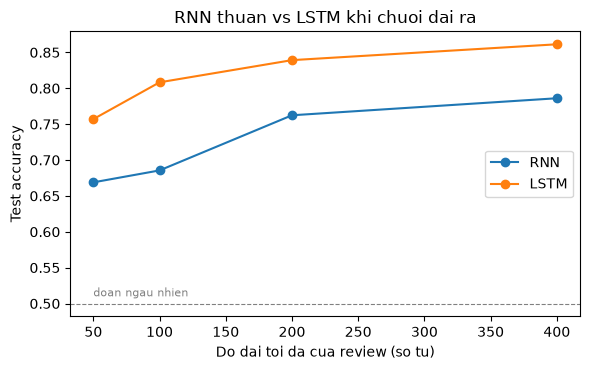

,rnn,lstm
50,0.6689,0.7570
100,0.6855,0.8083
200,0.7624,0.8392
400,0.7861,0.8613


In [3]:
stress = C.length_stress_test(data, lengths=(50, 100, 200, 400), kinds=('rnn', 'lstm'), epochs=6)
C.plot_stress(stress)
pd.DataFrame(stress).round(4)

## 3. Mô hình chính: BiLSTM
LSTM **hai chiều**: một LSTM đọc xuôi, một đọc ngược, ghép hai trạng thái cuối lại. Mỗi từ được hiểu theo cả ngữ cảnh trước và sau nó. Độ dài tối đa 400 từ.

In [4]:
loaders = data.loaders(max_len=400, batch_size=64)
C.set_seed(0)
lstm = C.RNNTextClassifier('lstm', len(data.itos), emb=128, hidden=128, layers=1, bidir=True, dropout=0.4)
print(f'{C.n_params(lstm):.2f}M tham số')

2.82M tham số


## 4. Huấn luyện
AdamW + OneCycleLR, cắt gradient, mixed precision. Chọn checkpoint theo val accuracy.

ep 01/8 | train loss 0.651 acc 0.600 | val loss 0.522 acc 0.732


ep 02/8 | train loss 0.501 acc 0.759 | val loss 0.464 acc 0.805


ep 03/8 | train loss 0.381 acc 0.830 | val loss 0.446 acc 0.844


ep 04/8 | train loss 0.308 acc 0.871 | val loss 0.410 acc 0.858


ep 05/8 | train loss 0.257 acc 0.896 | val loss 0.361 acc 0.876


ep 06/8 | train loss 0.223 acc 0.912 | val loss 0.373 acc 0.879


ep 07/8 | train loss 0.196 acc 0.923 | val loss 0.413 acc 0.882


ep 08/8 | train loss 0.184 acc 0.928 | val loss 0.416 acc 0.881
Thời gian train: 1.4 phút


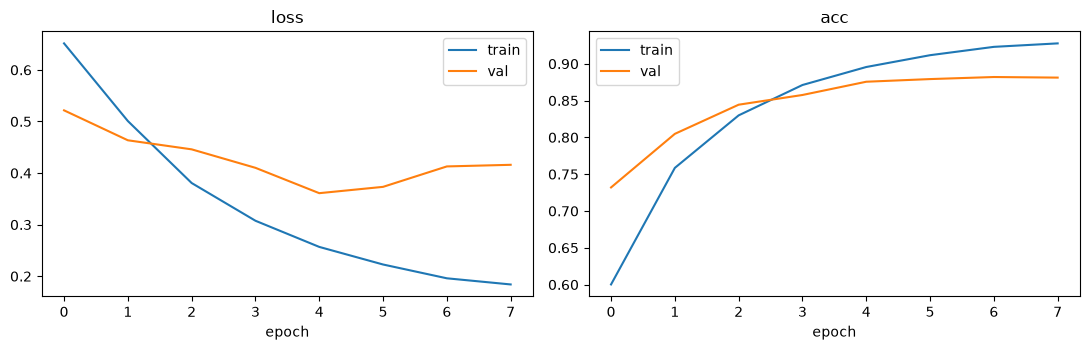

In [5]:
lstm, hist, t = C.train_classifier('lstm_imdb', lstm, loaders, epochs=8, lr=2e-3)
print(f'Thời gian train: {t/60:.1f} phút')
C.plot_history(hist)

## 5. Đánh giá trên tập test (25.000 review)

              precision    recall  f1-score   support

    negative     0.8795    0.8728    0.8761     12500
    positive     0.8738    0.8804    0.8771     12500

    accuracy                         0.8766     25000
   macro avg     0.8766    0.8766    0.8766     25000
weighted avg     0.8766    0.8766    0.8766     25000



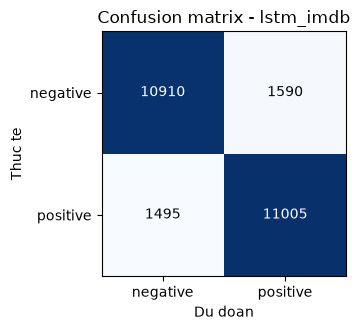

[lstm_imdb] test accuracy 0.8766 | macro F1 0.8766


In [6]:
res = C.evaluate_classifier('lstm_imdb', lstm, loaders['test'], hist, t)

In [7]:
C.predict_texts_rnn(lstm, data, [
    'A wonderful, moving film with brilliant acting.',
    'Total waste of time, awful acting and a boring plot.',
    'I expected to hate it, but it turned out to be surprisingly good.',
    'The first hour was slow and dull, however the ending completely won me over.',
], max_len=400)

positive (1.00) | A wonderful, moving film with brilliant acting.
negative (1.00) | Total waste of time, awful acting and a boring plot.
negative (0.58) | I expected to hate it, but it turned out to be surprisingly good.
negative (0.99) | The first hour was slow and dull, however the ending completely won me over.


## 6. Nhận xét

### Thí nghiệm RNN thuần và LSTM theo độ dài review (accuracy trên tập test)

| Độ dài tối đa | RNN | LSTM | LSTM hơn RNN |
|---|---|---|---|
| 50 từ | 0,669 | 0,757 | +8,8 điểm |
| 100 từ | 0,686 | 0,808 | +12,3 điểm |
| 200 từ | 0,762 | 0,839 | +7,7 điểm |
| 400 từ | 0,786 | 0,861 | +7,5 điểm |

- **LSTM tốt hơn RNN thuần ở mọi độ dài**, từ 7,5 đến 12,3 điểm accuracy.
- **Giả thuyết ban đầu không được xác nhận:** mình dự đoán khoảng cách sẽ tăng khi chuỗi dài ra, nhưng kết quả cho thấy khoảng cách **không tăng** (lớn nhất ở 100 từ, nhỏ nhất ở 400 từ). Cả hai mô hình đều tốt hơn khi nhìn được nhiều từ hơn, vì review dài chứa nhiều bằng chứng về cảm xúc hơn.
- **Vì sao:** phân loại cảm xúc không đòi hỏi nhiều mối liên hệ xa (từ tích cực nằm ở đầu hay cuối đều có giá trị). Thí nghiệm này cho thấy LSTM **huấn luyện ổn định và mạnh hơn** RNN thuần, nhưng chưa tách riêng được khả năng "nhớ xa". Để chứng minh điều đó cần bài toán có phụ thuộc xa thật sự (ví dụ nhớ một ký tự ở đầu chuỗi đến cuối chuỗi).
- Mỗi con số là một lần chạy với một seed, 6 epoch.

### Mô hình chính: BiLSTM (400 từ, 8 epoch)

- **Test accuracy 87,66%**, macro F1 0,877, 2,82 triệu tham số, train khoảng 1,4 phút.
- **Overfit nhẹ:** train accuracy cuối 92,8%, val 88,1% (val cao nhất 88,2% ở epoch 7). Val accuracy gần như phẳng từ epoch 5.
- **So với LSTM 1 chiều ở 400 từ (86,1%):** BiLSTM cao hơn khoảng 1,6 điểm, nhưng hai mô hình khác nhau ở cả chiều đọc, kích thước và số epoch nên không tách riêng được tác dụng của việc đọc hai chiều.

### Các câu thử

Mô hình đoán đúng hai câu rõ ràng (khen và chê) với độ tin cậy 1,00. Với hai câu có **chuyển ý** ("tôi tưởng sẽ ghét nhưng hóa ra rất hay" và "một giờ đầu chán nhưng đoạn kết chinh phục tôi"), BiLSTM **đoán sai cả hai** thành tiêu cực (độ tin cậy 0,58 và 0,99). Chỉ có 4 câu nên đây chỉ là minh họa, không phải kết luận thống kê.

**Kết luận:** LSTM ổn định và mạnh hơn RNN thuần trên văn bản dài, đạt khoảng 87,7% trên IMDB. Nó vẫn khó với câu có chuyển ý, điều mà Transformer ở notebook 03 xử lý tốt hơn trên các câu thử.